# 04 — Candidats et propagation d'analogues

**Le problème.** Pour ~84 % des molécules du test caché, aucun spectre de référence n'existe : la recherche d'identité du notebook 03 ne peut rien pour elles. Il faut donc :

1. **proposer des structures** qu'on n'a jamais vues mesurées : toutes celles du réservoir (train ∪ COCONUT) qui ont la bonne masse neutre ;
2. **les classer** sans pouvoir comparer leurs spectres, puisqu'elles n'en ont pas.

Pour classer, on s'appuie sur les **analogues** : les spectres de référence qui ressemblent le plus à la requête appartiennent souvent à des molécules **voisines** de la bonne réponse (même squelette, un groupe en plus ou en moins). On note alors chaque candidat selon sa ressemblance structurale avec ces analogues. C'est la « propagation d'analogues » des meilleurs notebooks publics.

Plan : (1) écrire les candidats comme les organisateurs écrivent les réponses, (2) construire le réservoir et mesurer sa couverture, (3) classer par analogues, (4) évaluer en conditions classe 2 et classe 1.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import casmi

pd.set_option("display.width", 140)

## 1. Écrire les candidats comme les réponses

On a découvert que **la clé du score peut dépendre de l'écriture** d'une molécule : la même lactone donne deux clés différentes selon que sa stéréochimie est écrite ou non. Or les SMILES du train ne contiennent **aucune** stéréochimie, alors que 83 % de ceux de COCONUT en ont.

Les organisateurs décrivent leurs SMILES comme « standardisés par RDKit ». On a cherché quelle normalisation RDKit laisse les SMILES du train **inchangés** : nettoyage, neutralisation des charges quand c'est possible, plus grand fragment, retrait de la stéréochimie (`casmi.normalize_smiles`). Elle laisse 100 % d'un échantillon de 20 000 SMILES du train intacts : c'est très probablement leur chaîne. On l'applique à COCONUT, et ce sont ces SMILES normalisés qu'on proposera.

In [2]:
structures = pd.read_parquet(casmi.paths.processed / "structures.parquet")
sample = structures["normalized_smiles"].sample(5000, random_state=1)
unchanged = (sample.map(casmi.normalize_smiles) == sample).mean()
print(f"SMILES du train inchangés par la normalisation : {unchanged:.2%}")

coco = pd.read_parquet(casmi.paths.processed / "coconut_norm.parquet")
old_keys = pd.read_parquet(casmi.paths.processed / "coconut_keys.parquet").set_index("normalized_smiles")["key"]
new_keys = pd.read_parquet(casmi.paths.processed / "coconut_norm_keys.parquet").set_index("normalized_smiles")["key"]
coco["key_original"] = coco["canonical_smiles"].map(old_keys)
coco["key_normalized"] = coco["smiles_norm"].map(new_keys)
changed = coco["key_original"] != coco["key_normalized"]
print(f"Entrées COCONUT : {len(coco):,}")
print(f"  SMILES modifiés par la normalisation : {(coco['canonical_smiles'] != coco['smiles_norm']).mean():.1%}")
print(f"  dont la clé du score change          : {changed.mean():.2%} ({changed.sum():,} entrées)")

SMILES du train inchangés par la normalisation : 100.00%


Entrées COCONUT : 716,694
  SMILES modifiés par la normalisation : 97.6%
  dont la clé du score change          : 1.25% (8,961 entrées)


**Lecture.** La normalisation modifie l'écriture de la grande majorité des entrées COCONUT (surtout en retirant la stéréochimie), mais la clé du score ne change que pour une petite fraction d'entre elles. Pour ces molécules-là, proposer l'écriture d'origine de COCONUT aurait pu être compté faux, si les réponses sont écrites comme le train.

## 2. Le réservoir de candidats

Réservoir = structures du train ∪ COCONUT normalisé, une ligne par clé du score (`casmi.candidate_pool`). Pour chaque molécule de validation :

- **masse neutre** : médiane des masses déduites de chacun de ses spectres (précurseur − adduit) ;
- **candidats** : toutes les structures du réservoir à **±10 ppm** de cette masse.

**Couverture** : la bonne réponse est-elle parmi les candidats ? En condition classe 2, elle devrait presque toujours y être (sa structure est dans le réservoir). En condition classe 3, par définition, jamais.

In [3]:
pool = casmi.candidate_pool()
fps = casmi.pool_fingerprints(pool)
print(f"Réservoir : {len(pool):,} structures "
      f"(train : {pool['in_train'].sum():,}, COCONUT : {pool['in_coconut'].sum():,}, les deux : {(pool['in_train'] & pool['in_coconut']).sum():,})")

val_structures, val_queries = casmi.load_validation()
masses = casmi.molecule_masses(val_queries)
pool_mass = pool["exact_mass"].to_numpy()
pool_keys = pool["key"].to_numpy()

cov = val_structures.set_index("molecule_id")[["key", "subset"]].copy()
cov["mass_error_ppm"] = (masses - val_structures.set_index("molecule_id")["exact_mass"]) / masses * 1e6
cov["n_candidates"] = [len(casmi.candidates_in_window(pool_mass, masses[m])) for m in cov.index]
cov["truth_in_candidates"] = [k in set(pool_keys[casmi.candidates_in_window(pool_mass, masses[m])])
                              for m, k in cov["key"].items()]
print(cov.groupby("subset").agg(couverture=("truth_in_candidates", "mean"),
                                candidats_médiane=("n_candidates", "median"),
                                candidats_max=("n_candidates", "max"),
                                erreur_masse_ppm_médiane=("mass_error_ppm", lambda x: x.abs().median())).round(3))

Réservoir : 705,405 structures (train : 274,195, COCONUT : 456,521, les deux : 25,311)
               couverture  candidats_médiane  candidats_max  erreur_masse_ppm_médiane
subset                                                                               
A_np_examples       1.000               56.5            392                     1.491
B_np_public         0.989               52.0            731                     0.459


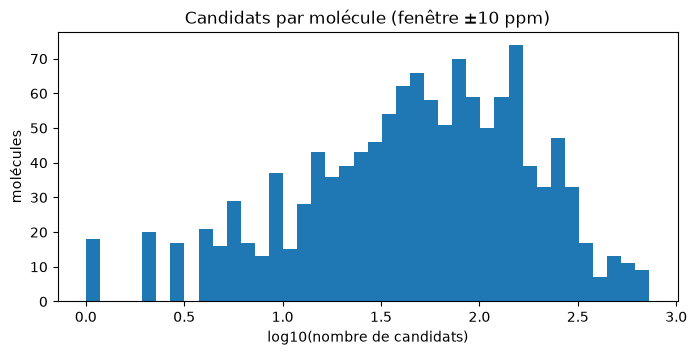

MRR@25 d'un classement au hasard parmi les candidats (classe 2) :
  A_np_examples : 0.118
  B_np_public : 0.148


In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(cov["n_candidates"].clip(lower=1)), bins=40)
ax.set(title="Candidats par molécule (fenêtre ±10 ppm)", xlabel="log10(nombre de candidats)", ylabel="molécules")
plt.show()

print("MRR@25 d'un classement au hasard parmi les candidats (classe 2) :")
for s, g in cov.groupby("subset"):
    print(f"  {s} : {casmi.random_mrr(g['n_candidates'].to_numpy(), g['truth_in_candidates'].to_numpy()):.3f}")

Classer au hasard donne un score proche de zéro : il y a en général des dizaines à des centaines de structures de la même masse. C'est tout l'enjeu : **distinguer des isomères**.

## 3. Propagation d'analogues

Pour chaque spectre requête, la **recherche hybride** (notebook 03) parcourt toute la bibliothèque, toutes masses confondues, et trouve les spectres les plus ressemblants, en comptant les pics communs **et** les pics décalés de la différence de masse (typique de deux molécules qui diffèrent d'un groupe chimique). On garde les 100 meilleurs, et pour chaque structure trouvée (analogue *a*) sa meilleure similarité.

Puis, pour chaque candidat *c* de la fenêtre de masse (`casmi.analog_propagation`) :

$$\text{score}(c) = \sum_{a} \Big(\sum_{q} \text{sim}(q, a)^4\Big) \cdot \text{Tanimoto}(c, a)$$

- **sim(q, a)** : similarité spectrale entre le spectre requête *q* et l'analogue *a* ; la puissance 4 donne un poids écrasant aux analogues très ressemblants ;
- **Tanimoto(c, a)** : ressemblance structurale entre le candidat et l'analogue, mesurée sur leurs **empreintes de Morgan** (la liste des petits motifs d'atomes présents dans chaque molécule) ; 1 = mêmes motifs, 0 = aucun en commun.

La recherche hybride coûte ~0,2 s par spectre, soit ~8 minutes par tirage et par condition. On évalue sur deux tirages.

In [5]:
meta = casmi.load_train_meta(["ingest_lib", "normalized_smiles", "ionization_mode", "instrument_type"])
meta["key"] = meta["normalized_smiles"].map(structures.set_index("normalized_smiles")["key"])
meta["source"] = meta["ingest_lib"] + " / " + casmi.instrument_family(meta["instrument_type"])
library = casmi.build_clean_library()
index = casmi.SpectralIndex(library, meta)
row_keys = meta["key"].to_numpy()
counts = casmi.spectra_count_distribution()
masks = {c: casmi.reference_mask(meta, val_queries, c) for c in ["class1", "class2"]}

In [6]:
SEEDS = [0, 1]
hybrid, identity = {}, {}
for seed in SEEDS:
    draw = casmi.sample_queries(val_queries, counts, seed)
    for cond, allowed in masks.items():
        t = time.time()
        hybrid[(cond, seed)] = casmi.spectrum_hits(index, library, row_keys, draw, allowed,
                                                   method="hybrid", top_hits=100)
        identity[(cond, seed)] = casmi.spectrum_hits(index, library, row_keys, draw, allowed)
        print(f"tirage {seed} {cond} : {time.time() - t:.0f} s")

tirage 0 class1 : 881 s


tirage 0 class2 : 910 s


tirage 1 class1 : 1028 s


tirage 1 class2 : 1510 s


In [7]:
truth = val_structures.set_index("molecule_id")["key"].to_dict()
rows = []
for (cond, seed), hits in hybrid.items():
    for power in [1, 2, 4, 8]:
        scores = casmi.analog_propagation(hits, masses, pool, fps, power=power)
        ev = casmi.evaluate(scores, val_structures)
        rows.append(ev.assign(condition=cond, seed=seed, method=f"analogues (puissance {power})"))
    # classe 3 : la bonne structure est retirée des candidats
    if cond == "class2":
        scores = casmi.analog_propagation(hits, masses, pool, fps, power=4, excluded=truth)
        rows.append(casmi.evaluate(scores, val_structures).assign(condition="class3", seed=seed,
                                                                   method="analogues (puissance 4)"))
results = pd.concat(rows, ignore_index=True)
(results.groupby(["condition", "method", "subset", "seed"])["rr"].mean()
        .groupby(["condition", "method", "subset"]).mean().unstack("subset").round(3))

subset                             A_np_examples  B_np_public
condition method                                             
class1    analogues (puissance 1)          0.757        0.591
          analogues (puissance 2)          0.780        0.631
          analogues (puissance 4)          0.813        0.669
          analogues (puissance 8)          0.845        0.688
class2    analogues (puissance 1)          0.536        0.456
          analogues (puissance 2)          0.549        0.474
          analogues (puissance 4)          0.557        0.496
          analogues (puissance 8)          0.570        0.510
class3    analogues (puissance 4)          0.000        0.000

## 4. Le pipeline complet : identité d'abord, analogues ensuite

Pour le test caché, on ne sait pas à quelle classe appartient chaque molécule. Le pipeline doit donc faire les deux :

- si la recherche d'**identité** trouve une référence de même masse très ressemblante (classe 1), on lui fait confiance ;
- sinon, le classement par **analogues** prend le relais (classe 2).

Combinaison simple : score final = score d'identité × 10 + score d'analogues normalisé (entre 0 et 1). Un candidat retrouvé par identité passe donc devant tous les autres ; les autres sont départagés par les analogues. On vérifie que cette combinaison garde le niveau de chaque méthode dans sa condition.

In [8]:
def combine(id_scores, an_scores, w_identity=10.0):
    out = {}
    for mol, an in an_scores.items():
        top = max(an.values(), default=0) or 1.0
        s = {k: v / top for k, v in an.items()}
        for k, v in id_scores.get(mol, {}).items():
            s[k] = s.get(k, 0.0) + w_identity * v
        out[mol] = s
    return out

rows = []
for (cond, seed), hits in hybrid.items():
    an = casmi.analog_propagation(hits, masses, pool, fps, power=4)
    idn = casmi.aggregate_hits(identity[(cond, seed)], "sum")
    for name, sc in [("identité seule", idn), ("analogues seuls", an), ("identité + analogues", combine(idn, an))]:
        rows.append(casmi.evaluate(sc, val_structures).assign(condition=cond, seed=seed, method=name))
pipeline = pd.concat(rows, ignore_index=True)
(pipeline.groupby(["condition", "method", "subset", "seed"])["rr"].mean()
         .groupby(["condition", "method", "subset"]).mean().unstack("subset").round(3))

subset                          A_np_examples  B_np_public
condition method                                          
class1    analogues seuls               0.813        0.669
          identité + analogues          0.930        0.602
          identité seule                0.928        0.495
class2    analogues seuls               0.557        0.496
          identité + analogues          0.195        0.242
          identité seule                0.000        0.000

## 5. Où se perdent les points en classe 2 ?

Trois cas d'échec possibles : la bonne réponse n'est pas parmi les candidats (couverture), elle y est mais au-delà du rang 25, ou elle est dans les 25 mais pas au rang 1.

In [9]:
c2 = pipeline[(pipeline["condition"] == "class2") & (pipeline["method"] == "identité + analogues")]

def bucket(r):
    if pd.isna(r):
        return "absente des candidats"
    return "rang 1" if r == 1 else ("rangs 2-25" if r <= 25 else "rang > 25")

c2 = c2.assign(résultat=c2["rank"].map(bucket))
(c2.groupby("subset")["résultat"].value_counts(normalize=True).unstack().round(3)
   .reindex(columns=["rang 1", "rangs 2-25", "rang > 25", "absente des candidats"]))

résultat,rang 1,rangs 2-25,rang > 25,absente des candidats
subset,,,,
A_np_examples,0.066,0.740,0.194,NaN
B_np_public,0.115,0.659,0.215,0.011


## Ce qu'on retient

- Les candidats sont écrits comme les réponses (normalisation retrouvée à partir du train).
- En classe 2, la bonne réponse est presque toujours parmi les candidats : le problème est de la **classer**.
- La propagation d'analogues fait passer le score de ~0 (hasard) à un niveau utile ; le pipeline identité + analogues garde la classe 1 intacte.

**Prochaine étape** : empaqueter ce pipeline dans un notebook Kaggle (hors ligne) pour une **première soumission**, puis améliorer le classement avec un classeur appris (notebook 05).